### **Naveed Anjum (Reg # 577607)**
##### Oct 7, 2026
---
## **Tutorial 7: Feature Extraction vs. Fine-Tuning**

## Step 1 — Import Libraries

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, datasets
import matplotlib.pyplot as plt
import numpy as np
import time

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
QUICK = False        # True → use a small subset and 1 epoch (fast test)

device: cuda


## Step 2 — Load and Preprocess the Dataset

In [2]:
# Load CIFAR-10 dataset
train_set = datasets.CIFAR10("data", train=True, download=True)
test_set = datasets.CIFAR10("data", train=False, download=True)

x_train = torch.tensor(train_set.data).permute(0, 3, 1, 2).float() / 255.0     # [50000, 3, 32, 32] in 0..1
x_test = torch.tensor(test_set.data).permute(0, 3, 1, 2).float() / 255.0
y_train = torch.tensor(train_set.targets)
y_test = torch.tensor(test_set.targets)
y_train_onehot = F.one_hot(y_train, 10)          # to_categorical(y_train, 10)
y_test_onehot = F.one_hot(y_test, 10)

if QUICK:
    x_train, y_train, x_test, y_test = x_train[:2000], y_train[:2000], x_test[:1000], y_test[:1000]

x_train, y_train, x_test, y_test = x_train.to(device), y_train.to(device), x_test.to(device), y_test.to(device)
print(x_train.shape, y_train.shape, y_train_onehot[0])

100%|██████████| 170M/170M [46:29<00:00, 61.1kB/s]


torch.Size([50000, 3, 32, 32]) torch.Size([50000]) tensor([0, 0, 0, 0, 0, 0, 1, 0, 0, 0])


In [3]:
def evaluate(model, x, y):
    # model.evaluate(x, y) -> loss, accuracy
    model.eval()
    loss, correct = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(x), 500):
            out = model(x[i:i + 500])
            loss += F.cross_entropy(out, y[i:i + 500], reduction="sum").item()
            correct += (out.argmax(1) == y[i:i + 500]).sum().item()
    return loss / len(x), correct / len(x)

def fit(model, x, y, epochs=10, lr=1e-3, batch_size=32, validation_data=None, weight_decay=0.0, patience=None, name=""):
    # model.fit(x, y, epochs=..., validation_data=..., batch_size=...) with Adam optimizer + cross-entropy loss
    if QUICK: epochs = 1
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    history = {"train_acc": [], "val_acc": []}
    best_acc, best_state, bad = -1, None, 0
    for epoch in range(epochs):
        model.train()
        for m in model.modules():                       # frozen BatchNorm stays in eval mode
            if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
                m.eval()
        perm = torch.randperm(len(x), device=device)
        for i in range(0, len(x), batch_size):
            idx = perm[i:i + batch_size]
            loss = F.cross_entropy(model(x[idx]), y[idx])
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        _, train_acc = evaluate(model, x, y)
        _, val_acc = evaluate(model, *validation_data)
        history["train_acc"].append(train_acc); history["val_acc"].append(val_acc)
        print(f"{name} epoch {epoch + 1}/{epochs}  train acc {train_acc:.4f}  val acc {val_acc:.4f}")
        if patience:                                     # early stopping: keep the best epoch
            if val_acc > best_acc:
                best_acc, bad = val_acc, 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= patience: print("early stopping"); break
    if patience and best_state: model.load_state_dict(best_state)
    return history

---
## Step 3 — Load Pretrained Models
### Feature extraction using pretrained VGG16

In [4]:
# Feature extraction with VGG16
base_model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features      # include_top=False
for param in base_model.parameters():                                                # layer.trainable = False
    param.requires_grad = False

# Add new classification layers:  Flatten -> Dense(512, relu) -> Dense(10)   (softmax is inside the loss)
model_feature_extraction = nn.Sequential(base_model, nn.Flatten(), nn.Linear(512, 512), nn.ReLU(), nn.Linear(512, 10)).to(device)

# Train the model (only the new layers are trained)
history_feature_extraction = fit(model_feature_extraction, x_train, y_train, epochs=10, lr=1e-3, batch_size=32,
                                 validation_data=(x_test, y_test), name="VGG16 FE")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 88.4MB/s]


VGG16 FE epoch 1/10  train acc 0.6320  val acc 0.6080
VGG16 FE epoch 2/10  train acc 0.6720  val acc 0.6208
VGG16 FE epoch 3/10  train acc 0.7073  val acc 0.6291
VGG16 FE epoch 4/10  train acc 0.7435  val acc 0.6414
VGG16 FE epoch 5/10  train acc 0.7642  val acc 0.6383
VGG16 FE epoch 6/10  train acc 0.7943  val acc 0.6305
VGG16 FE epoch 7/10  train acc 0.8320  val acc 0.6365
VGG16 FE epoch 8/10  train acc 0.8499  val acc 0.6313
VGG16 FE epoch 9/10  train acc 0.8729  val acc 0.6300
VGG16 FE epoch 10/10  train acc 0.8889  val acc 0.6290


### Fine-tuning using pretrained ResNet50

In [5]:
# Fine-Tuning with ResNet50 (without top fully connected layers)
resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
base_model = nn.Sequential(*list(resnet.children())[:-2])          # include_top=False
for param in base_model.parameters():
    param.requires_grad = False

# Add new classification layers
model_finetune = nn.Sequential(base_model, nn.Flatten(), nn.Linear(2048, 512), nn.ReLU(), nn.Linear(512, 10)).to(device)

# Unfreeze the last layers of ResNet50 (Keras' last 5 layers = the last conv + batch-norm of the final block)
last_block = base_model[-1][-1]
for layer in [last_block.conv3, last_block.bn3]:
    for param in layer.parameters():
        param.requires_grad = True

# Train the model: last layers + new layers are updated, Adam(1e-5)
history_finetune = fit(model_finetune, x_train, y_train, epochs=10, lr=1e-5, batch_size=32,
                       validation_data=(x_test, y_test), name="ResNet50 FT")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 187MB/s]


ResNet50 FT epoch 1/10  train acc 0.5512  val acc 0.5439
ResNet50 FT epoch 2/10  train acc 0.5874  val acc 0.5752
ResNet50 FT epoch 3/10  train acc 0.6100  val acc 0.5882
ResNet50 FT epoch 4/10  train acc 0.6267  val acc 0.5992
ResNet50 FT epoch 5/10  train acc 0.6393  val acc 0.6029
ResNet50 FT epoch 6/10  train acc 0.6490  val acc 0.6090
ResNet50 FT epoch 7/10  train acc 0.6619  val acc 0.6146
ResNet50 FT epoch 8/10  train acc 0.6707  val acc 0.6223
ResNet50 FT epoch 9/10  train acc 0.6782  val acc 0.6192
ResNet50 FT epoch 10/10  train acc 0.6897  val acc 0.6238


## Step 4 — Evaluate Both Models

In [6]:
# Evaluate both models
loss_feature_extraction, acc_feature_extraction = evaluate(model_feature_extraction, x_test, y_test)
loss_finetune, acc_finetune = evaluate(model_finetune, x_test, y_test)

## Step 5 — Compare Results

In [7]:
print(f"Feature Extraction Accuracy: {acc_feature_extraction * 100:.2f}%")
print(f"Fine-Tuning Accuracy: {acc_finetune * 100:.2f}%")

Feature Extraction Accuracy: 62.90%
Fine-Tuning Accuracy: 62.38%


## Task 1 — Improving the fine-tuning results

In [8]:
n_val = 200 if QUICK else 5000
x_tr, y_tr, x_val, y_val = x_train[:-n_val], y_train[:-n_val], x_train[-n_val:], y_train[-n_val:]
mean = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

class Net(nn.Module):
    # base_model -> Flatten -> Dense(512, relu) -> [Dropout] -> Dense(10)   (same head as the tutorial)
    def __init__(self, base_model, feat_dim, dropout=0.0, normalize=False):
        super().__init__()
        self.base_model, self.normalize = base_model, normalize
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(feat_dim, 512), nn.ReLU(), nn.Dropout(dropout), nn.Linear(512, 10))
    def forward(self, x):
        if self.normalize:
            x = (x - mean) / std                     # preprocessing: ImageNet mean/std
        return self.head(self.base_model(x))

def get_resnet50_base():
    return nn.Sequential(*list(models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1).children())[:-2])

def get_vgg16_base():
    return models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features

def freeze(base_model):
    for param in base_model.parameters():
        param.requires_grad = False

def finetune_resnet(lr=1e-5, unfreeze="last", normalize=False, dropout=0.0, weight_decay=0.0, epochs=5, patience=None):
    base_model = get_resnet50_base(); freeze(base_model)
    model = Net(base_model, 2048, dropout, normalize).to(device)
    # base_model children: conv1, bn1, relu, maxpool, layer1, layer2, layer3, layer4
    if unfreeze == "last":
        layers = [base_model[-1][-1].conv3, base_model[-1][-1].bn3]            # tutorial: last layers only
    else:
        layers = list(base_model.children())[{"layer4": 7, "layer3+4": 6, "all": 0}[unfreeze]:]
    for layer in layers:
        for param in layer.parameters():
            param.requires_grad = True
    fit(model, x_tr, y_tr, epochs=epochs, lr=lr, validation_data=(x_val, y_val), weight_decay=weight_decay,
        patience=patience, name=f"[{unfreeze} lr={lr}]")
    return evaluate(model, x_test, y_test)[1]          # test accuracy

In [9]:
experiments = {
    "baseline (tutorial: lr 1e-5)":      dict(),
    "learning rate 1e-4":                dict(lr=1e-4),
    "learning rate 1e-3":                dict(lr=1e-3),
    "ImageNet normalisation":            dict(normalize=True),
    "dropout 0.5 + weight decay":        dict(dropout=0.5, weight_decay=1e-4),
    "20 epochs + early stopping":        dict(epochs=20, patience=3),
    "unfreeze layer4":                   dict(unfreeze="layer4"),
    "unfreeze layer3+4":                 dict(unfreeze="layer3+4"),
    "unfreeze all layers":               dict(unfreeze="all"),
}
results = {name: finetune_resnet(**kw) for name, kw in experiments.items()}

[last lr=1e-05] epoch 1/5  train acc 0.5437  val acc 0.5494
[last lr=1e-05] epoch 2/5  train acc 0.5829  val acc 0.5772
[last lr=1e-05] epoch 3/5  train acc 0.6051  val acc 0.5984
[last lr=1e-05] epoch 4/5  train acc 0.6211  val acc 0.6070
[last lr=1e-05] epoch 5/5  train acc 0.6329  val acc 0.6180
[last lr=0.0001] epoch 1/5  train acc 0.6197  val acc 0.5990
[last lr=0.0001] epoch 2/5  train acc 0.6636  val acc 0.6262
[last lr=0.0001] epoch 3/5  train acc 0.7014  val acc 0.6228
[last lr=0.0001] epoch 4/5  train acc 0.7356  val acc 0.6322
[last lr=0.0001] epoch 5/5  train acc 0.7549  val acc 0.6358
[last lr=0.001] epoch 1/5  train acc 0.5971  val acc 0.5880
[last lr=0.001] epoch 2/5  train acc 0.6615  val acc 0.6290
[last lr=0.001] epoch 3/5  train acc 0.6943  val acc 0.6354
[last lr=0.001] epoch 4/5  train acc 0.7412  val acc 0.6428
[last lr=0.001] epoch 5/5  train acc 0.7720  val acc 0.6422
[last lr=1e-05] epoch 1/5  train acc 0.6526  val acc 0.6462
[last lr=1e-05] epoch 2/5  train ac

[layer4 lr=0.0001] epoch 1/20  train acc 0.8371  val acc 0.7730
[layer4 lr=0.0001] epoch 2/20  train acc 0.8962  val acc 0.7804
[layer4 lr=0.0001] epoch 3/20  train acc 0.9413  val acc 0.7864
[layer4 lr=0.0001] epoch 4/20  train acc 0.9673  val acc 0.7946
[layer4 lr=0.0001] epoch 5/20  train acc 0.9757  val acc 0.7738
[layer4 lr=0.0001] epoch 6/20  train acc 0.9843  val acc 0.7768
[layer4 lr=0.0001] epoch 7/20  train acc 0.9900  val acc 0.7860
early stopping
 59.92%  baseline (tutorial: lr 1e-5)
 62.77%  learning rate 1e-4
 63.95%  learning rate 1e-3
 68.69%  ImageNet normalisation
 59.04%  dropout 0.5 + weight decay
 63.11%  20 epochs + early stopping
 66.83%  unfreeze layer4
 73.75%  unfreeze layer3+4
 78.47%  unfreeze all layers
 77.62%  COMBINED


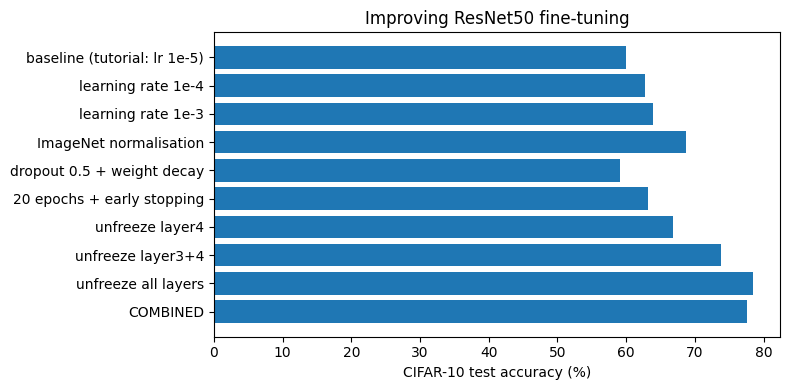

In [10]:
results["COMBINED"] = finetune_resnet(lr=1e-4, normalize=True, unfreeze="layer4", dropout=0.5, weight_decay=1e-4, epochs=20, patience=3)

for name, acc in results.items():
    print(f"{acc * 100:6.2f}%  {name}")
plt.figure(figsize=(8, 4))
plt.barh(list(results)[::-1], [100 * a for a in results.values()][::-1]); plt.xlabel("CIFAR-10 test accuracy (%)")
plt.title("Improving ResNet50 fine-tuning"); plt.tight_layout(); plt.show()

---
## Task 2 — ResNet50 feature extraction vs. a custom model vs. VGG16

* **ResNet50 feature extraction**: pretrained ResNet50 frozen, only the new layers are trained.
* **Custom model**: a small CNN trained from scratch.
* **VGG16 feature extraction**: already trained in Step 3.

In [11]:
# ResNet50 feature extraction
base_model = get_resnet50_base(); freeze(base_model)
model_resnet_fe = Net(base_model, 2048).to(device)
history_resnet_fe = fit(model_resnet_fe, x_train, y_train, epochs=10, lr=1e-3, validation_data=(x_test, y_test), name="ResNet50 FE")

# Custom model (trained from scratch)
custom = nn.Sequential(
    nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      # 32x32 -> 16x16
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # -> 8x8
    nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # -> 4x4
)
model_custom = Net(custom, 128 * 4 * 4).to(device)
history_custom = fit(model_custom, x_train, y_train, epochs=10, lr=1e-3, validation_data=(x_test, y_test), name="Custom CNN")

ResNet50 FE epoch 1/10  train acc 0.6249  val acc 0.6005
ResNet50 FE epoch 2/10  train acc 0.6613  val acc 0.6124
ResNet50 FE epoch 3/10  train acc 0.6906  val acc 0.6256
ResNet50 FE epoch 4/10  train acc 0.7147  val acc 0.6272
ResNet50 FE epoch 5/10  train acc 0.7377  val acc 0.6332
ResNet50 FE epoch 6/10  train acc 0.7480  val acc 0.6244
ResNet50 FE epoch 7/10  train acc 0.7720  val acc 0.6257
ResNet50 FE epoch 8/10  train acc 0.7847  val acc 0.6198
ResNet50 FE epoch 9/10  train acc 0.8215  val acc 0.6233
ResNet50 FE epoch 10/10  train acc 0.8532  val acc 0.6291
Custom CNN epoch 1/10  train acc 0.5734  val acc 0.5641
Custom CNN epoch 2/10  train acc 0.6945  val acc 0.6644
Custom CNN epoch 3/10  train acc 0.7480  val acc 0.7038
Custom CNN epoch 4/10  train acc 0.7963  val acc 0.7271
Custom CNN epoch 5/10  train acc 0.8175  val acc 0.7276
Custom CNN epoch 6/10  train acc 0.8411  val acc 0.7325
Custom CNN epoch 7/10  train acc 0.8716  val acc 0.7304
Custom CNN epoch 8/10  train acc 0.90

ResNet50 feature extraction: 62.91%
Custom model (from scratch): 74.28%
VGG16 feature extraction:    62.90%


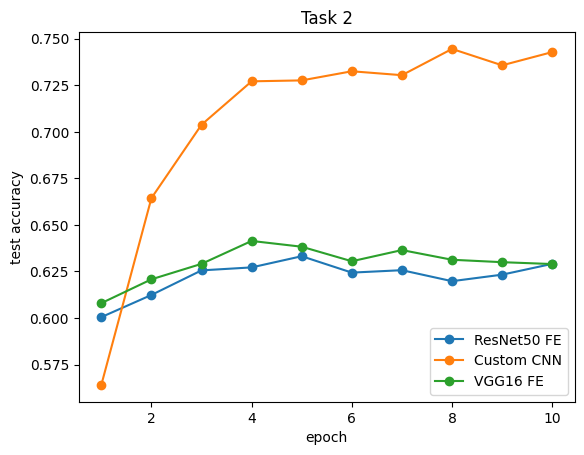

In [12]:
acc_resnet_fe = evaluate(model_resnet_fe, x_test, y_test)[1]
acc_custom = evaluate(model_custom, x_test, y_test)[1]
print(f"ResNet50 feature extraction: {acc_resnet_fe * 100:.2f}%")
print(f"Custom model (from scratch): {acc_custom * 100:.2f}%")
print(f"VGG16 feature extraction:    {acc_feature_extraction * 100:.2f}%")

for name, h in [("ResNet50 FE", history_resnet_fe), ("Custom CNN", history_custom), ("VGG16 FE", history_feature_extraction)]:
    plt.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "-o", label=name)
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.legend(); plt.title("Task 2"); plt.show()

## Task 3 — Fine-tuning with VGG16 and feature extraction with ResNet50

In [13]:
base_model = get_vgg16_base(); freeze(base_model)
model_vgg_ft = Net(base_model, 512).to(device)
for layer in list(base_model.children())[24:]:          # block 5 (conv5_1, conv5_2, conv5_3)
    for param in layer.parameters():
        param.requires_grad = True
history_vgg_ft = fit(model_vgg_ft, x_train, y_train, epochs=10, lr=1e-5, validation_data=(x_test, y_test), name="VGG16 FT")
acc_vgg_ft = evaluate(model_vgg_ft, x_test, y_test)[1]

VGG16 FT epoch 1/10  train acc 0.7127  val acc 0.6968
VGG16 FT epoch 2/10  train acc 0.7488  val acc 0.7274
VGG16 FT epoch 3/10  train acc 0.7838  val acc 0.7494
VGG16 FT epoch 4/10  train acc 0.7979  val acc 0.7562
VGG16 FT epoch 5/10  train acc 0.8127  val acc 0.7599
VGG16 FT epoch 6/10  train acc 0.8286  val acc 0.7714
VGG16 FT epoch 7/10  train acc 0.8431  val acc 0.7770
VGG16 FT epoch 8/10  train acc 0.8576  val acc 0.7832
VGG16 FT epoch 9/10  train acc 0.8663  val acc 0.7777
VGG16 FT epoch 10/10  train acc 0.8753  val acc 0.7797


CIFAR-10 test accuracy (%)


,Feature extraction,Fine-tuning
VGG16,62.90,77.97
ResNet50,62.91,62.38


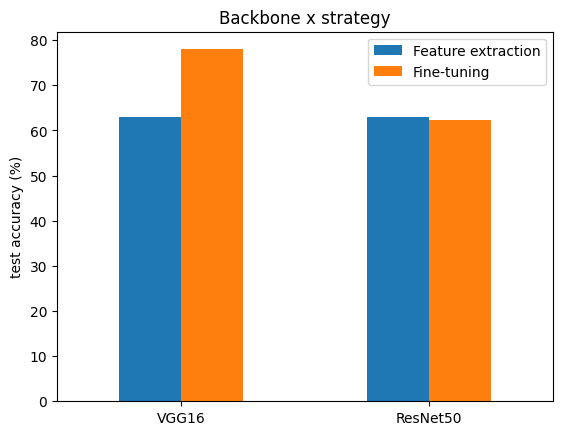

Custom model: 74.28% | ResNet50 fine-tuning with improvements (Task 1): 77.62%


In [14]:
import pandas as pd
table = pd.DataFrame({"Feature extraction": [acc_feature_extraction, acc_resnet_fe], "Fine-tuning": [acc_vgg_ft, acc_finetune]},
                     index=["VGG16", "ResNet50"]) * 100
print("CIFAR-10 test accuracy (%)"); display(table.round(2))
table.plot.bar(rot=0); plt.ylabel("test accuracy (%)"); plt.title("Backbone x strategy"); plt.show()
print(f"Custom model: {acc_custom * 100:.2f}% | ResNet50 fine-tuning with improvements (Task 1): {results['COMBINED'] * 100:.2f}%")